# STEP 1 - Data Generation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
import os
import sys

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *

Loading satellites/
Aspect ratio:  5
Ratio of rotational diffusion:  0.06769699908603415
Ratio of orthogonal diffusion:  0.7664558871581453


# Simulate Data

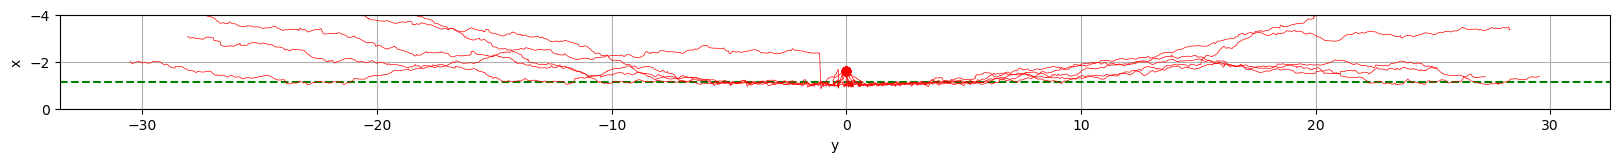

In [2]:
#@njit
def run_abp(n_trajectories, n_steps, dt, x0, y0, phi0,
            Pe, Dt, Dr, force_strength, torque_params
           ):
    
    X = np.zeros((n_trajectories, n_steps))
    Y = np.zeros((n_trajectories, n_steps))
    PHI = np.zeros((n_trajectories, n_steps))

    X[:, 0] = x0
    Y[:, 0] = y0
    PHI[:, 0] = phi0

    for t in range(1, n_steps):

        # Calulate WCA wall force
        F = np.zeros(n_trajectories)
        for k in prange(n_trajectories):
            if X[k, t-1] > -2**(1/6):
                F[k] = -24 * force_strength * (X[k, t-1]**6 - 2) / X[k, t-1]**13

        # Update position

        vx = np.cos(PHI[:, t-1]) * Pe
        vy = np.sin(PHI[:, t-1]) * Pe


        X[:, t] = X[:, t-1] + vx * dt + np.sqrt(2 * Dt * dt) * np.random.normal(size=n_trajectories) + F * dt
        Y[:, t] = Y[:, t-1] + vy * dt + np.sqrt(2 * Dt * dt) * np.random.normal(size=n_trajectories)

        # Update orientation
        torque = np.zeros(n_trajectories)
        for k in prange(n_trajectories):
            torque[k] = Q2 * ratio_diff_rot**2 * TORQUE(PHI[k, t-1], torque_params) * F[k]

        PHI[:, t] = PHI[:, t-1] + torque * dt + np.sqrt(2 * Dr * dt * ratio_diff_rot) * np.random.normal(size=n_trajectories)

    return X, Y, PHI

def plot_trajectory(x, y, phi):
    
    plt.plot(y.T[0], x.T[0], 'ro')
    plt.axhline(-2**(1/6), color='g', linestyle='--')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.grid()
    #plt.ylim(None, 0)

    tangent_length = 0.5
    n_steps = x.shape[0]
    #for i in range(0, n_steps, 10):
    #    plt.plot([y[i], y[i] + tangent_length*np.sin(phi[i])],
    #             [x[i], x[i] + tangent_length*np.cos(phi[i])],
    #             'b', alpha=0.5, linewidth=0.8)

    plt.plot(y.T, x.T, 'r', lw=0.5)
    plt.xlabel('y')
    plt.ylabel('x')
    plt.gca().invert_yaxis()



phi0 = PHI0
np.random.seed(12345)
x_data, y_data, phi_data = run_abp(n_trajectories, n_steps, dt, X0, Y0, phi0, PE, DT, DR, FORCE_STRENGTH, ALPHAS)
plt.figure(figsize=(20, 20))
plot_trajectory(x_data, y_data, phi_data)
plt.ylim(-4, 0)
plt.gca().invert_yaxis()
plt.savefig('step_1_trajectories.png', dpi=600)
plt.show()

# Pickle everything

In [3]:
payload = dict(
    ALPHAS=ALPHAS,
    n_trajectories=n_trajectories,
    n_steps=n_steps,
    dt=dt,
    X0=X0,
    Y0=Y0,
    PHI0=PHI0,
    PE=PE,
    DT=DT,
    DR=DR,
    FORCE_STRENGTH=FORCE_STRENGTH,
    x_data=x_data,
    y_data=y_data,
    phi_data=phi_data,
    Q2=Q2,
)
np.savez('../GLOBAL/data.npz', **payload)